In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the architectural image and the image to be projected
building_path = 'a2images/building1.jpg'
overlay_path = 'a2images/overlay1.jpg'

building = cv2.imread(building_path)
overlay = cv2.imread(overlay_path)

if building is None or overlay is None:
    raise FileNotFoundError("Check the image paths and filenames.")

print("Background image size:", building.shape)
print("Overlay image size:", overlay.shape)

Background image size: (480, 680, 3)
Overlay image size: (3334, 5000, 3)


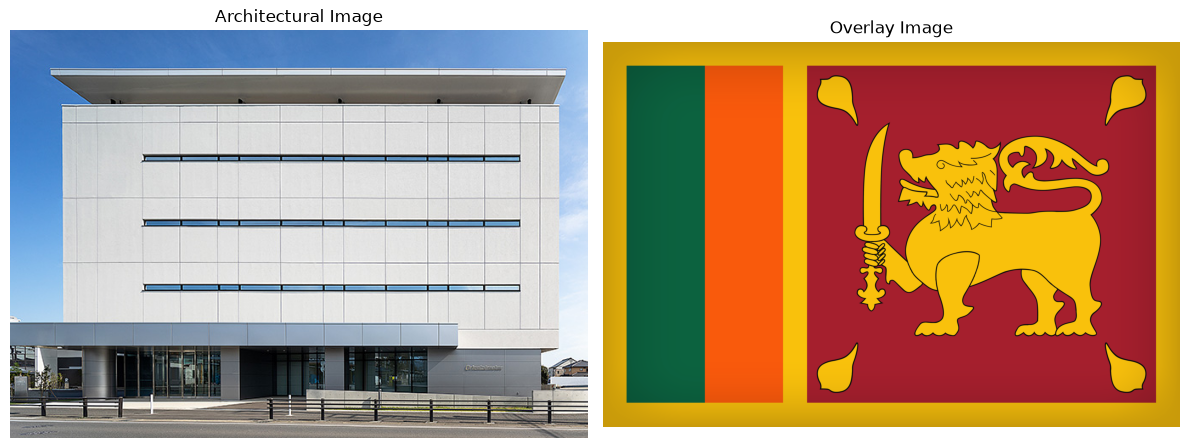

In [2]:
# Display both input images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(building, cv2.COLOR_BGR2RGB))
plt.title("Architectural Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Overlay Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [3]:
# Make a copy for displaying the selected points
display_image = building.copy()
selected_points = []

def choose_corners(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN and len(selected_points) < 4:
        selected_points.append([x, y])

        # Mark the selected corner
        cv2.circle(display_image, (x, y), 6, (0, 255, 0), -1)
        cv2.putText(
            display_image,
            str(len(selected_points)),
            (x + 8, y - 8),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 0, 255),
            2
        )

        cv2.imshow("Select four corners", display_image)
        print(f"Selected point {len(selected_points)}: ({x}, {y})")

# Open the image window
cv2.namedWindow("Select four corners")
cv2.imshow("Select four corners", display_image)
cv2.setMouseCallback("Select four corners", choose_corners)

print("Click the four surface corners in clockwise order.")
print("Press any key after selecting all four points.")

while len(selected_points) < 4:
    if cv2.waitKey(20) & 0xFF == 27:
        break

cv2.waitKey(0)
cv2.destroyAllWindows()

if len(selected_points) != 4:
    raise ValueError("Exactly four points must be selected.")

destination_points = np.array(selected_points, dtype=np.float32)

# Get the four corners of the overlay image
overlay_height, overlay_width = overlay.shape[:2]

source_points = np.array([
    [0, 0],
    [overlay_width - 1, 0],
    [overlay_width - 1, overlay_height - 1],
    [0, overlay_height - 1]
], dtype=np.float32)

# Compute the homography mapping overlay coordinates to the surface
H, status = cv2.findHomography(source_points, destination_points)

if H is None:
    raise RuntimeError("Homography estimation failed.")

print("Homography matrix:")
print(H)

Click the four surface corners in clockwise order.
Press any key after selecting all four points.
Selected point 1: (156, 108)
Selected point 2: (517, 109)
Selected point 3: (517, 275)
Selected point 4: (156, 275)
Homography matrix:
[[ 7.28374591e-02 -1.36283707e-17  1.56000000e+02]
 [ 3.31391580e-04  5.01050105e-02  1.08000000e+02]
 [ 1.20506029e-06 -4.05003587e-20  1.00000000e+00]]


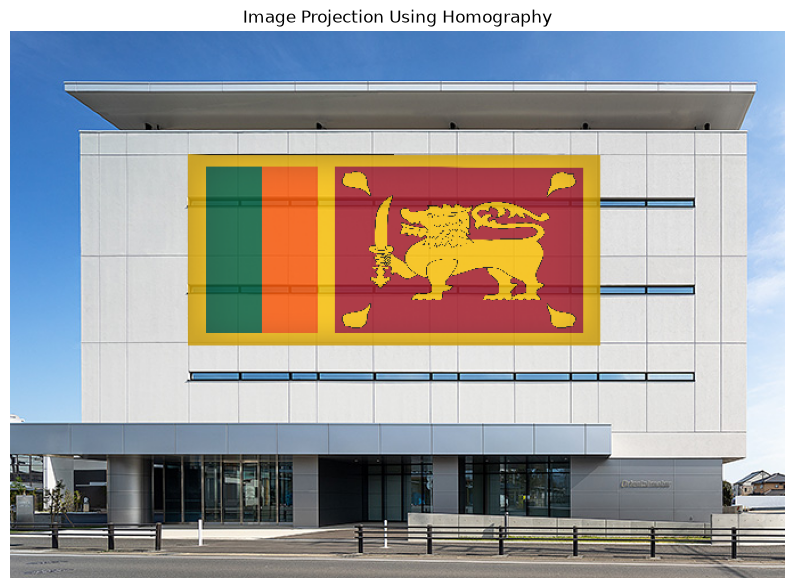

Result saved as: homography_result1.png


In [4]:
# Warp the overlay into the background image coordinates
height, width = building.shape[:2]

warped_overlay = cv2.warpPerspective(
    overlay,
    H,
    (width, height)
)

# Create a mask for the projected quadrilateral
surface_mask = np.zeros((height, width), dtype=np.uint8)

cv2.fillConvexPoly(
    surface_mask,
    destination_points.astype(np.int32),
    255
)

# Blend only within the selected surface
alpha = 0.85

result = building.copy()

region = surface_mask > 0

result[region] = cv2.addWeighted(
    building[region],
    1 - alpha,
    warped_overlay[region],
    alpha,
    0
)

# Display the final composite
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Image Projection Using Homography")
plt.axis("off")
plt.show()

# Save the result
output_path = "homography_result1.png"
cv2.imwrite(output_path, result)

print("Result saved as:", output_path)